# Simulação de Sistema DRUPS (Diesel Rotary UPS) - 50 MW

Este notebook apresenta a modelagem matemática e a simulação de um sistema de armazenamento de energia cinética utilizando um motor de indução com rotor externo operando como acoplamento eletromagnético.

**Autor:** Sgpt (Assistente Técnico de Angelo Alfredo Hafner)  
**Data:** 13 de Agosto de 2026

---

## 1. Intuição Física

Imagine o sistema como uma **embreagem magnética variável**.

*   **O Estator:** Está montado no eixo principal, girando a 1800 RPM (sincronismo de 60Hz/4 polos).
*   **O Rotor Externo:** É uma massa enorme (inércia) girando livremente a uma velocidade superior (ex: 3200 RPM).

Quando a energia da rede falha, injetamos Corrente Contínua (CC) no estator. Isso cria um campo magnético que "tenta" frear o rotor externo. Pela Terceira Lei de Newton, a força que freia o rotor é a mesma que empurra o estator para frente, mantendo o eixo principal girando e alimentando a carga de 50MW através da máquina síncrona.

## 2. Modelagem Matemática

### 2.1. Potências e Torque
Para manter uma carga constante de $P_{util} = 50\text{ MW}$ a uma velocidade síncrona $\omega_s$, o torque necessário é:
$$T_L = \frac{P_{util}}{\omega_s}$$

### 2.2. Fluxo de Energia
A potência total extraída da inércia ($P_{total}$) é maior que a entregue à carga, pois há perdas por escorregamento:
1. **Potência Útil:** $P_{util} = T_L \cdot \omega_s$
2. **Potência de Perda (Calor):** $P_{heat} = T_L \cdot (\omega_r - \omega_s)$
3. **Potência Total:** $P_{total} = P_{util} + P_{heat} = T_L \cdot \omega_r$

### 2.3. Dinâmica da Velocidade
A desaceleração do rotor externo de inércia $J_r$ segue:
$$\frac{d\omega_r}{dt} = -\frac{T_L}{J_r}$$

### 2.4. Energia Disponível
A energia útil não é a cinética total, mas a relativa à velocidade de operação:
$$E_{disp} = \frac{1}{2} J_r (\omega_r^2 - \omega_s^2)$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# --- Parâmetros de Entrada ---
P_load = 50e6          # 50 MW
freq = 60              # Hz
poles = 4
duration = 30          # segundos de rampa alvo

# Velocidade Síncrona (rad/s)
omega_s = (120 * freq / poles) * (2 * np.pi / 60)
torque_req = P_load / omega_s

# Estimativa de Inércia para 50MW
Jr = 125000            # kg.m^2
omega_r0 = 3200 * (2 * np.pi / 60) # RPM inicial

# --- Simulação ---
t = np.linspace(0, 40, 500)
omega_r = omega_r0 - (torque_req / Jr) * t

# Filtrar apenas enquanto omega_r > omega_s
mask = omega_r >= omega_s
t_sim = t[mask]
omega_r_sim = omega_r[mask]

# Cálculos Derivados
energy_avail = 0.5 * Jr * (omega_r_sim**2 - omega_s**2)
p_heat = torque_req * (omega_r_sim - omega_s)
efficiency = (omega_s / omega_r_sim) * 100

print(f"Simulação configurada para {P_load/1e6} MW")
print(f"Torque constante no eixo: {torque_req/1e3:.2f} kNm")

Simulação configurada para 50.0 MW
Torque constante no eixo: 265.26 kNm


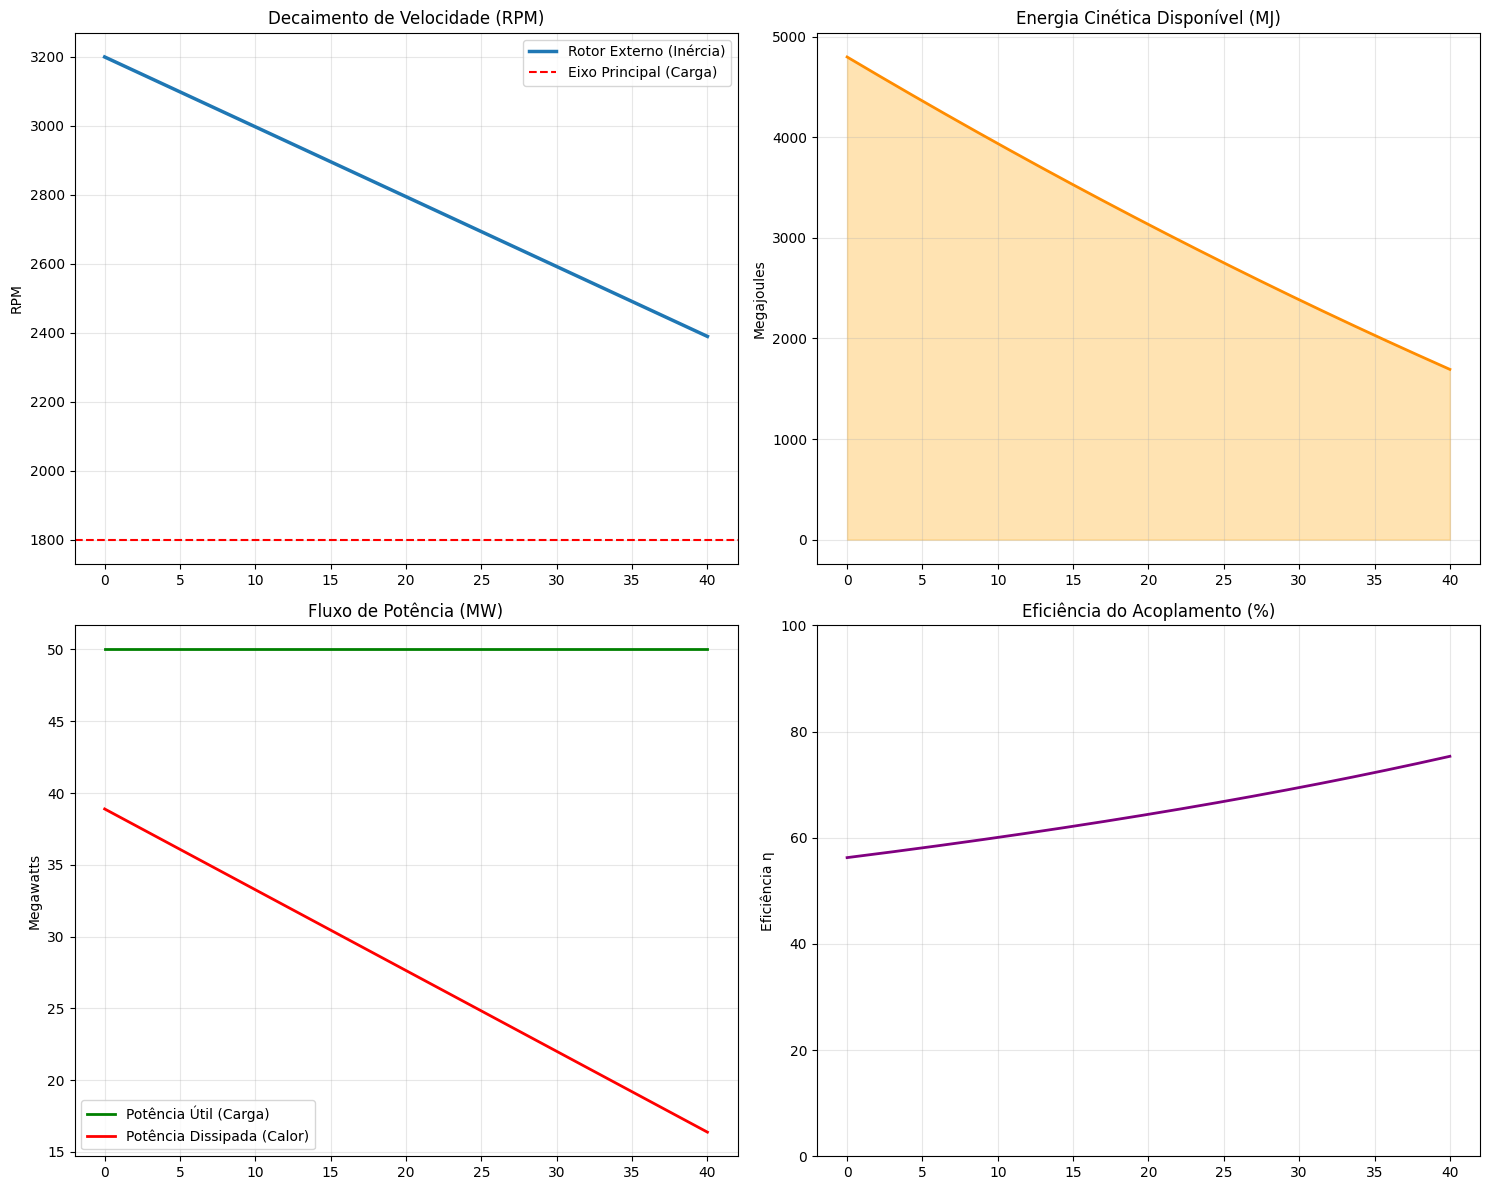

In [3]:
# --- Visualização Didática ---
fig, axs = plt.subplots(2, 2, figsize=(15, 12))

# 1. Velocidades
axs[0, 0].plot(t_sim, omega_r_sim * 60 / (2*np.pi), label='Rotor Externo (Inércia)', lw=2.5)
axs[0, 0].axhline(y=1800, color='r', linestyle='--', label='Eixo Principal (Carga)')
axs[0, 0].set_title("Decaimento de Velocidade (RPM)")
axs[0, 0].set_ylabel("RPM")
axs[0, 0].legend()
axs[0, 0].grid(True, alpha=0.3)

# 2. Energia Disponível
axs[0, 1].fill_between(t_sim, energy_avail / 1e6, color='orange', alpha=0.3)
axs[0, 1].plot(t_sim, energy_avail / 1e6, color='darkorange', lw=2)
axs[0, 1].set_title("Energia Cinética Disponível (MJ)")
axs[0, 1].set_ylabel("Megajoules")
axs[0, 1].grid(True, alpha=0.3)

# 3. Fluxo de Potência (Útil vs Calor)
axs[1, 0].plot(t_sim, [P_load/1e6]*len(t_sim), 'g', label='Potência Útil (Carga)', lw=2)
axs[1, 0].plot(t_sim, p_heat / 1e6, 'r', label='Potência Dissipada (Calor)', lw=2)
axs[1, 0].set_title("Fluxo de Potência (MW)")
axs[1, 0].set_ylabel("Megawatts")
axs[1, 0].legend()
axs[1, 0].grid(True, alpha=0.3)

# 4. Eficiência do Acoplamento
axs[1, 1].plot(t_sim, efficiency, color='purple', lw=2)
axs[1, 1].set_title("Eficiência do Acoplamento (%)")
axs[1, 1].set_ylabel("Eficiência η")
axs[1, 1].set_ylim(0, 100)
axs[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Conclusões e Notas de Engenharia

### 3.1. O Desafio Térmico
Observe o gráfico de **Fluxo de Potência**. No início da rampa ($t=0$), a dissipação de calor é de quase **40 MW**.
*   Isso significa que o rotor externo está agindo como um aquecedor massivo.
*   A energia total dissipada em 30s é a área sob a curva vermelha (centenas de Megajoules).
*   **Solução:** O rotor deve ter uma massa térmica muito grande ou um sistema de resfriamento ativo extremamente potente.

### 3.2. A Questão Elétrica (400V vs 50MW)
Para 50MW em 400V:
$$I = \frac{50.000.000}{\sqrt{3} \cdot 400 \cdot 1.0} \approx 72.168 \text{ Amperes}$$
*   **Crítica:** Correntes desta magnitude exigiriam barramentos de cobre do tamanho de vigas de prédio.
*   **Recomendação:** Em um projeto real de 50MW, a tensão de geração seria **13.800V**, reduzindo a corrente para **~2.100A**, o que é o padrão industrial para essa potência.